# 03 · Calibration

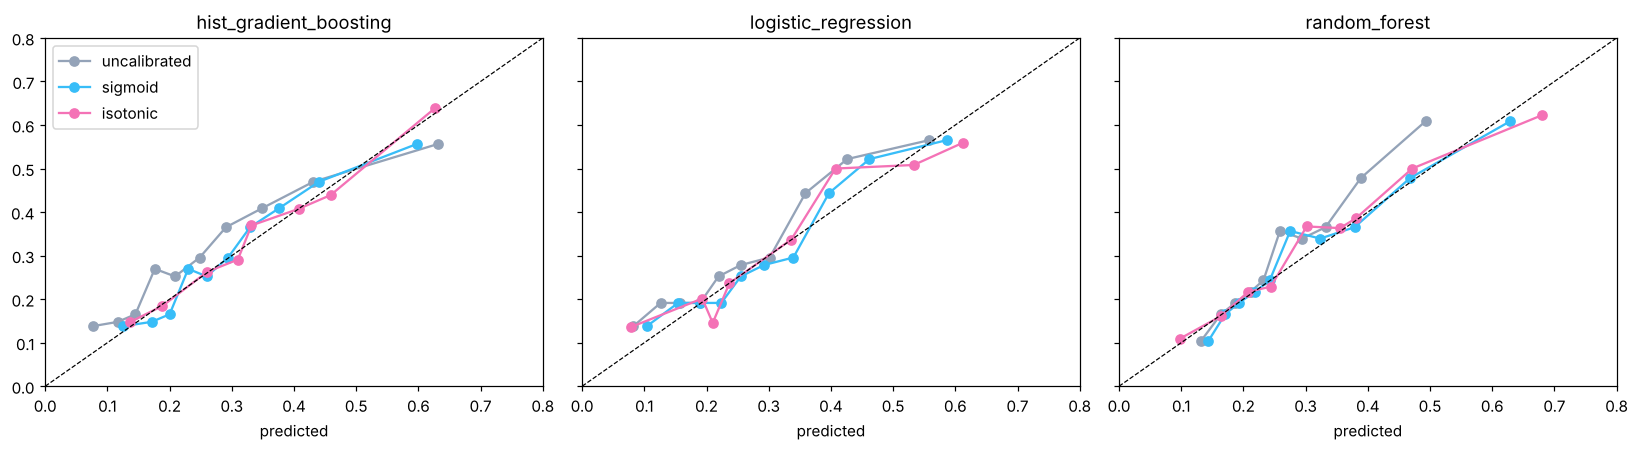

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from medpredict.common.config import get_settings
from medpredict.storage.database import Database

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
db = Database(get_settings().db_path)
c = db.query_df("SELECT * FROM calibration_curves")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
colors = {"uncalibrated": "#94a3b8", "sigmoid": "#38bdf8", "isotonic": "#f472b6"}
for ax, (m, g) in zip(axes, c.groupby("model")):
    for r in g.itertuples():
        ax.plot(json.loads(r.predicted), json.loads(r.observed), "o-", label=r.calibration, color=colors[r.calibration])
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    ax.set(title=m, xlim=(0, .8), ylim=(0, .8), xlabel="predicted")
axes[0].legend()
plt.tight_layout()

In [2]:
r = db.query_df("SELECT model, calibration, metrics_json FROM model_results")
pd.DataFrame([{"model": a, "calibration": b, "ece": json.loads(j)["ece"], "brier": json.loads(j)["brier"],
               "slope": json.loads(j)["cal_slope"]} for a, b, j in zip(r.model, r.calibration, r.metrics_json)]).round(4)